In [1]:
import sys
import cirq
import numpy as np
import matplotlib.pyplot as plt
import itertools

sys.path.append("../")
# import resource_estimation as res
import resource_estimation.ftqc.compile_ftqc as comp
import resource_estimation.ftqc.architecture as arch
import resource_estimation.ftqc.layout as lyt
import resource_estimation.ftqc.codepatch as cpa
import resource_estimation.ftqc.mappers as mps

In [2]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

In [3]:
# # Functions like this are basically solutions to the mapping step of compilation
# # We do an initial static mapping of roles here, but a better compiler would dynamically assign roles during computation
# def initialize_context(circuit, layout, t_cultivation_factories, t_distillation_factories, ccz_distillation_factories, arc, surface_code_program_qubits, **kwargs):
#     if t_cultivation_factories and t_distillation_factories:
#         raise ValueError("Current compilation does not support two type of T generation")
#     num_program_qubits = cirq.num_qubits(circuit)
#     total_surface_code_patches = (
#         surface_code_program_qubits  # Logical qubits required by the circuit
#         + t_cultivation_factories  # Patches dedicated to T state cultivation
#         + 31 * t_distillation_factories  # 15 ancilla + 15 Cult + 1 Out
#         + 23 * ccz_distillation_factories  # 8 Cult + 12 Ancilla + 3 Out
#     )
#     patches_in_layout = len([p for p in layout.placements.values() if isinstance(p.element, cpa.RotatedSurfaceCodePatch)])
#     assert patches_in_layout == total_surface_code_patches, f"{patches_in_layout} != {total_surface_code_patches}"
#     qid_to_pid = {}
#     roles = {}
#     counter = 0
#     for qid in circuit.all_qubits():
#         qid_to_pid[qid] = counter
#         roles[counter] = 1
#         counter += 1
#     for idx in range(t_cultivation_factories):
#         qid = cirq.NamedQubit(f"ct{idx}")
#         qid_to_pid[qid] = counter
#         roles[counter] = 4
#         counter += 1
#     for idx in range(t_distillation_factories*31):
#         qid = cirq.NamedQubit(f"dt{idx}")
#         qid_to_pid[qid] = counter
#         roles[counter] = 4
#         counter += 1
#     for idx in range(ccz_distillation_factories*23):
#         qid = cirq.NamedQubit(f"ccz{idx}")
#         qid_to_pid[qid] = counter
#         roles[counter] = 5
#         counter += 1
#     pid_to_qid = {pid: qid for qid, pid in qid_to_pid.items()}
#     return comp.Context(
#         roles=roles,
#         qid_to_pid=qid_to_pid,
#         pid_to_qid=pid_to_qid,
#         factories={},
#         blocks={},
#         distil_t=t_distillation_factories>0,
#         cult_t=t_cultivation_factories>0,
#         dynamic=False,
#         transversal_cnot=cirq.CX in arc.primitives,
#         num_ccz_factories=ccz_distillation_factories,
#         num_t_factories=t_cultivation_factories or t_distillation_factories
#     )

In [4]:
# def initialize_column_context(
#     circuit, layout, arc, **kwargs,
# ):
#     expected_rows = cirq.num_qubits(circuit) + cirq.num_qubits(circuit) %2
#     expected_cols = 7
#     expected_length = 2*arc.d-1
#     def get_patch_id_at(logical_row, logical_col):
#         anchor_row, anchor_col = logical_row*expected_length, logical_col*expected_length
#         match_placements = {obj for obj in layout.placements.values() if obj.row == anchor_row and obj.col == anchor_col}
#         assert len(match_placements) == 1
#         return match_placements.pop().element.patch_id
#     qid_to_pid = {}
#     roles = {}
#     role_cycle = itertools.cycle([
#         3, 2, 1, 2, 1, 2, 3, # SAQAQAS
#         4, 2, 2, 2, 2, 2, 4  # TAAAAAT
#     ])
#     qid_iter = iter(circuit.all_qubits())
    
#     for logical_row in range(expected_rows):
#         for logical_col in range(expected_cols):
#             pid = get_patch_id_at(logical_row, logical_col)
#             role_index = next(role_cycle)
            
#             roles[pid] = role_index
#             if role_index == 1:
#                 try:
#                     qid = next(qid_iter)
#                 except StopIteration:  # Overwrite non-existant qubit
#                     qid = cirq.NamedQubit(f"{logical_row}-{logical_col}-{2}")
#                     roles[pid] = 2
#             else:
#                 qid = cirq.NamedQubit(f"{logical_row}-{logical_col}-{role_index}")
#             qid_to_pid[qid] = pid
#     pid_to_qid = {pid: qid for qid, pid in qid_to_pid.items()}
#     return comp.Context(
#         roles=roles,
#         qid_to_pid=qid_to_pid,
#         pid_to_qid=pid_to_qid,
#         factories={},
#         blocks={},
#         distil_t=False,
#         cult_t=True,
#         dynamic=False,
#         transversal_cnot=False,
#         num_ccz_factories=0,
#         num_t_factories=2*expected_rows,
#     )
            
    

In [5]:
def plot_layout(layout: lyt.Layout, context: mps.Context):
    fig, ax = plt.subplots()
    clrs = {
        1: "skyblue",
        2: "gray",
        3: "navy",
        4: "orchid",
        5: "wheat",
    }
    for p in layout.placements.values():
        rect = Rectangle(
            (p.col, p.row),
            width=p.element.footprint.cols,
            height=p.element.footprint.rows,
            edgecolor="black",
            facecolor=clrs[context.roles[p.element.patch_id]],
            alpha=0.5,
        )
        ax.add_patch(rect)
    for p in layout.regions.values():
        rect = Rectangle(
            (p.col, p.row),
            width=p.element.footprint.cols,
            height=p.element.footprint.rows,
            edgecolor="black",
            facecolor="red",
            alpha=0.5,
        )
        ax.add_patch(rect)
        ax.text(
            p.col + p.element.footprint.cols / 2,
            p.row + p.element.footprint.rows / 2,
            str(p.element.role),  # Replace with your desired label
            ha="center",
            va="center",
            fontsize=8,
            color="black",
        )
    ax.autoscale_view()
    ax.set_aspect("equal")
    ax.invert_yaxis()  # Row 0 at the top
    # ax.grid(True)
    # plt.show()

In [6]:
q1, q2, q3 = cirq.LineQubit.range(3)
m_circuit = cirq.Circuit(
    cirq.H.on(q1),
    cirq.CCZ.on(q1, q2, q3),
    cirq.CCZ.on(q1, q2, q3),
    cirq.CCZ.on(q1, q2, q3),
    cirq.T.on(q1), 
    cirq.CNOT.on(q1, q2),
    cirq.measure(q1),
)
l_circuit = cirq.Circuit(
    cirq.H.on(q1),
    cirq.T.on(q1), 
    cirq.CNOT.on(q1, q2),
    cirq.measure(q1),
)
print(m_circuit)

0: ───H───@───@───@───T───@───M───
          │   │   │       │
1: ───────@───@───@───────X───────
          │   │   │
2: ───────@───@───@───────────────


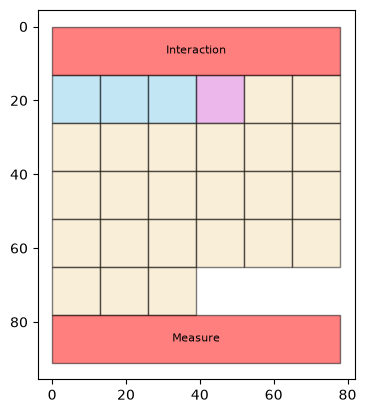

In [7]:
## Movement Keyword Arguments ##
m_dynamic = False
m_surface_code_program_qubits = cirq.num_qubits(m_circuit)
m_surface_code_distance = 7
m_t_cultivation_factories = 1
m_t_distillation_factories = 0
m_ccz_distillation_factories = 1
m_interaction_zone = True
m_measure_zone = True

# This seems like a lot of information just to generate a Layout...
movement_layout = lyt.generate_movement_layout(
    surface_code_program_qubits=m_surface_code_program_qubits,
    surface_code_distance=m_surface_code_distance,
    t_cultivation_factories=m_t_cultivation_factories,
    t_distillation_factories=m_t_distillation_factories,
    ccz_distillation_factories=m_ccz_distillation_factories,
    interaction_zone=m_interaction_zone,
    measure_zone=m_measure_zone,
)
movement_context = mps.build_movement_context(
    circuit=m_circuit,
    layout=movement_layout,
    t_cultivation_factories=m_t_cultivation_factories,
    t_distillation_factories=m_t_distillation_factories,
    ccz_distillation_factories=m_ccz_distillation_factories,
    dynamic=m_dynamic,
)
movement_arc = arch.DefaultMovement(m_surface_code_distance)
plot_layout(movement_layout, movement_context)

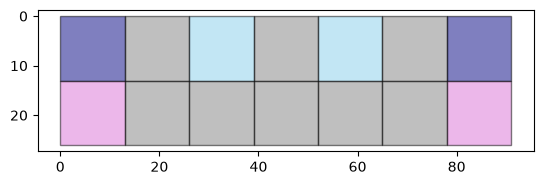

In [8]:
## Lattice Keyword Arguments ##
l_dynamic = False
l_surface_code_program_qubits = cirq.num_qubits(l_circuit)
l_surface_code_distance = 7

# This seems like a lot of information just to generate a Layout...
lattice_layout = lyt.generate_column_layout(
    surface_code_program_qubits=l_surface_code_program_qubits,
    surface_code_distance=l_surface_code_distance,
)
lattice_context = mps.build_column_context(
    circuit=l_circuit,
    layout=lattice_layout,
    surface_code_distance=l_surface_code_distance,
    dynamic=l_dynamic,
)
lattice_arc = arch.DefaultLattice(l_surface_code_distance)
plot_layout(lattice_layout, lattice_context)

In [9]:
# compiler_configs = {
#     "surface_code_distance": 7,
#     "t_cultivation_factories": 0,
#     "t_distillation_factories": 1,
#     "ccz_distillation_factories": 1,
#     "interaction_zone": True,
#     "measure_zone": True,
# }
# layout = lyt.generate_movement_layout(
#     surface_code_program_qubits=cirq.num_qubits(t_circuit),
#     **compiler_configs
# )
# # layout = lyt.generate_column_layout(
# #     surface_code_program_qubits=cirq.num_qubits(t_circuit),
# #     **compiler_configs,
# # )
# arc = arch.DefaultMovement(compiler_configs["surface_code_distance"])
# # arc = arch.DefaultLattice(compiler_configs["surface_code_distance"])
# context = initialize_context(
#     circuit=t_circuit,
#     layout=layout,
#     arc=arc,
#     surface_code_program_qubits=cirq.num_qubits(t_circuit),
#     **compiler_configs,
# )
# # context = initialize_column_context(
# #     circuit=t_circuit, 
# #     layout=layout, 
# #     arc=arc, 
# #     surface_code_program_qubits=cirq.num_qubits(t_circuit),
# #     **compiler_configs,
# # )
# # print(context)

In [10]:
# fig, ax = plt.subplots()
# clrs = {
#     1: "skyblue",
#     2: "gray",
#     3: "navy",
#     4: "orchid",
#     5: "wheat",
# }
# for p in layout.placements.values():
#     rect = Rectangle(
#         (p.col, p.row),
#         width=p.element.footprint.cols,
#         height=p.element.footprint.rows,
#         edgecolor="black",
#         facecolor=clrs[context.roles[p.element.patch_id]],
#         alpha=0.5,
#     )
#     ax.add_patch(rect)
# for p in layout.regions.values():
#     rect = Rectangle(
#         (p.col, p.row),
#         width=p.element.footprint.cols,
#         height=p.element.footprint.rows,
#         edgecolor="black",
#         facecolor="red",
#         alpha=0.5,
#     )
#     ax.add_patch(rect)
#     ax.text(
#         p.col + p.element.footprint.cols / 2,
#         p.row + p.element.footprint.rows / 2,
#         str(p.element.role),  # Replace with your desired label
#         ha="center",
#         va="center",
#         fontsize=8,
#         color="black",
#     )
# ax.autoscale_view()
# ax.set_aspect("equal")
# ax.invert_yaxis()  # Row 0 at the top
# # ax.grid(True)
# plt.show()

In [11]:
movement_compiled, movement_end_context = comp.ft_compile2(
    circuit=m_circuit,
    arc=movement_arc, 
    layout=movement_layout, 
    context=movement_context,
)

lattice_compiled, lattice_end_context = comp.ft_compile2(
    circuit=l_circuit,
    arc=lattice_arc,
    layout=lattice_layout,
    context=lattice_context,
)

In [12]:
# cirq.align_left(new_compiled)
movement_compiled

┌──────────────────┐   ┌──────────────────┐   ┌───┐   ┌──────────────────┐   ┌──────────────────┐                                                                                                                                                                                                                                                                                         ┌────────────┐   ┌────────────┐   ┌────────┐   ┌────────────┐   ┌────────────┐                                                                                                                                                                                                                                                                                    ┌────────────┐   ┌────────────┐   ┌────────┐   ┌────────────┐   ┌────────────┐
0: ───────SE(1)───H─────────────SE(1)───────────────────────────┤0   ├─────────────────X───────┤   1├───────────────────────────────────────SE(1)───H─────────────────────────SE(1)───X─────────────────────────SE(1)───┤0   ├────────────@─────────────────┤   1├───SE(1)───┤0   ├────────────@────────────┤   1├───SE(1)───H────────────────────────────────────────────SE(1)────────────┤0   ├───X───┤   1├────────────SE(1)────H───────────────────────────────────────────────────────────────────────────────SE(1)───X─────────────────────────SE(1)───SE(1)─────────────────────SE(1)───┤0   ├────────────@────────────┤   1├───SE(1)───┤0   ├─────────────────@────────────┤   1├───SE(1)───H───────────────────────────────────────SE(1)────────────┤0   ├───X───┤   1├────────────SE(1)────H───────────────────────────────────────────────────────────────────────────────SE(1)───X─────────────────────────SE(1)───SE(1)─────────────────────SE(1)───┤0   ├────────────@────────────┤   1├───SE(1)───┤0   ├────────────@────────────┤   1├───SE(1)───H───────────────────────────────────────SE(1)────────────┤0   ├───X───┤   1├────────────SE(1)───S─────────────────────────SE(1)───┤0   ├────────────@────────────┤   1├───SE(1)───┤0   ├───M───┤   1├───SE(1)───
                                                                                       │                                                                                                                                                  │                                                    │                                                                                                    │                                                                                                                                                                                                            │                                                    │                                                                                               │                                                                                                                                                                                                            │                                               │                                                                                               │                                                                                 │
1: ───────SE(1)───SE(1)─────────SE(1)─────────────────────────────────┤0   ├───────────┼X────────────┤   1├─────────────────────────────────SE(1)───H─────────────────────────SE(1)───X─────────────────────────SE(1)────────────┤0   ├───X────────┤   1├────────────SE(1)───SE(1)─────────────┼─────────────────────SE(1)───┤0   ├─────────────────@────────────┤   1├───SE(1)───H─────────────────┼─────────────────────SE(1)─────────────────────┤0   ├───────────X────────────┤   1├───────────────────────────SE(1)───H─────────────────────────SE(1)───X─────────────────────────SE(1)────────────┤0   ├───X───┤   1├────────────SE(1)───SE(1)──────────────────┼─────────────────────SE(1)───┤0   ├────────────@────────────┤   1├───SE(1)───H─────────────────┼─────────────────────SE(1)───────────

In [13]:
lattice_compiled

┌────────────────┐   ┌───────────────┐           ┌──────────┐           ┌──────────┐           ┌──────────┐           ┌──────────┐   ┌──────────┐
0: ───────SE(7)────H────────────────────MERGE──────────────SPLIT────SE(7)──────────────────MERGE─────────SE(7)────SPLIT─────────Z─────────────#2─────────────#2───────SE(7)───M───────SE(7)───
                                        │                  │                               │                      │                           │              │
1: ───────SE(7)───────────────MERGE─────┼────SPLIT─────────┼────────SE(7)──────────────────┼────SE(7)────SE(7)────┼────SE(7)────SE(7)────SE(7)┼─────────SE(7)┼────────SE(7)───SE(7)───SE(7)───
                              │         │    │             │                               │                      │                           │              │
0-0-3: ────────────CULT(1.571)┼─────────┼────┼────SE(7)────┼────────SE(7)──────────────────┼────SE(7)────SE(7)────┼────SE(7)────#2───────#2───┼─────────M('')┼────────SE(7)───R───────SE(7)───
                              │         │    │             │                               │                      │             │        │    │              │
0-1-2: ───────────────────────┼─────────#2───┼─────────────#2───────MERGE─────────SPLIT────#2─────────────────────#2────────────MERGE────SPLIT┼──────────────┼────────────────────────────────
                              │         │    │             │        │             │                                                           │              │
0-3-2: ───────────────────────#2────────┼────#2────────────┼────────┼─────────────┼───────────────────────────────────────────────────────────MERGE──────────SPLIT────────────────────────────
                                        │                  │        │             │
0-6-3: ────────────SE(7)────────────────┼────SE(7)─────────┼────────┼────SE(7)────┼────────SE(7)─────────SE(7)────SE(7)─────────SE(7)────SE(7)──────────SE(7)─────────SE(7)───SE(7)───SE(7)───
                                        │                  │        │             │
1-0-4: ────────────CULT(0.785)──────────┼────SE(7)─────────┼────────#3────────────#3───────M('')─────────SE(7)────R─────────────SE(7)────SE(7)──────────SE(7)─────────SE(7)───SE(7)───SE(7)───
                                        │                  │        │             │
1-1-2: ─────────────────────────────────#3─────────────────#3───────#2────────────#2──────────────────────────────────────────────────────────────────────────────────────────────────────────

1-6-4: ────────────SE(7)────────────────SE(7)───────────────────────SE(7)──────────────────SE(7)─────────SE(7)────SE(7)─────────SE(7)────SE(7)──────────SE(7)─────────SE(7)───SE(7)───SE(7)───
                  └────────────────┘   └───────────────┘           └──────────┘           └──────────┘           └──────────┘           └──────────┘   └──────────┘

In [14]:
import resource_estimation.ftqc.estimate as est
import resource_estimation.analysis as ans

In [15]:
estimator = est.ResourceEstimator(arc=movement_arc)
gate_cost = estimator.parallel_circuit_cost(movement_compiled, layout=movement_layout, context=movement_end_context)
pretty_gate_cost = {ans.make_pretty(key): val for key, val in gate_cost.items()}
circuit_time = estimator.parallel_circuit_time(movement_compiled, layout=movement_layout, context=movement_end_context)
physical_qubits = estimator.physical_qubits(movement_compiled)

In [16]:
print("Gates")
for op, count in sorted(gate_cost.items(), key=lambda x: x[1], reverse=True):
    op = ans.make_pretty(op)
    print(f"{op}{' ' * (25 - len(op))}{count:.2e}")
print("*" * 33)
print("Metrics")
print(f"Time (μs){' ' * 16}{circuit_time:.2e}\nQubits{' ' * 19}{physical_qubits:.2e}")

Gates
MovementGate             1.37e+03
CZ                       5.21e+02
PhasedXZGate             2.20e+02
MeasurementGate          9.20e+01
ResetChannel             8.90e+01
*********************************
Metrics
Time (μs)                8.68e+05
Qubits                   3.78e+03


In [17]:
estimator = est.ResourceEstimator(arc=lattice_arc)
gate_cost = estimator.parallel_circuit_cost(lattice_compiled, layout=lattice_layout, context=lattice_end_context)
pretty_gate_cost = {ans.make_pretty(key): val for key, val in gate_cost.items()}
circuit_time = estimator.parallel_circuit_time(lattice_compiled, layout=lattice_layout, context=lattice_end_context)
physical_qubits = estimator.physical_qubits(lattice_compiled)

In [18]:
print("Gates")
for op, count in sorted(gate_cost.items(), key=lambda x: x[1], reverse=True):
    op = ans.make_pretty(op)
    print(f"{op}{' ' * (25 - len(op))}{count:.2e}")
print("*" * 33)
print("Metrics")
print(f"Time (μs){' ' * 16}{circuit_time:.2e}\nQubits{' ' * 19}{physical_qubits:.2e}")

Gates
CZ                       3.36e+02
PhasedXZGate             1.69e+02
MeasurementGate          8.70e+01
ResetChannel             8.70e+01
*********************************
Metrics
Time (μs)                1.23e+05
Qubits                   8.73e+02
